In [1]:
from common import *

### Motif analysis

In [2]:
compute = True

In [3]:
def atom_latex_name(s):
    return f"\mathrm{{{s[0]}}}_\mathrm{{{s[1:]}}}"

def motif_latex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"${atom_latex_name(name)}^\mathrm{{{resname}{resid}}}$" for resname, resid, name in zip(resnames, resids, names))
    if x['stereo']:
        motif = x['stereo'] + "-" + motif
    return motif

def motif_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"{resname}{resid}{name}" for resname, resid, name in zip(resnames, resids, names))
    if mgrna:
        motif += '-' + mgrna
    return motif

def summarize_motifs(df):
    df['motif'] = df.apply(motif_name, axis=1).astype('category')

    # Create a unique id for each block of data for error estimate
    df['block'], _ = pd.factorize(df[['replicate', 'repid']].apply(tuple, axis='columns'))

    count = df.groupby(['block', 'time', 'motif'], observed=True).size()
    count = count.unstack('motif', fill_value=0)

    p_block = count.groupby('block').mean()
    block_weight = count.groupby('block').size().rename('block_weight')
    block_weight /= block_weight.sum()

    p = p_block.mul(block_weight, axis='index').sum().rename('p')

    # Error estimate: bayesian bootstrap with blocks
    ci = p_block.apply(
        lambda x: tuple(map(float, bayesian_bootstrap(x, np.average, weights=block_weight).confidence_interval))
    ).transpose().set_axis(['p_low', 'p_high'], axis='columns')

    n_block_obs = (p_block > 0).sum().rename('n_block_obs')

    res = pd.concat([p, ci, n_block_obs], axis='columns')

    res = res.join(
        df.drop_duplicates(subset='motif', keep='first').set_index('motif')[['n_inner', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames', 'stereo', 'mgrna']]
    )

    mg_indices = df.groupby('motif', observed=True)['index'].agg(lambda x: list(set(x))).rename('mg_indices')
    res = res.join(mg_indices)

    return res


### Summary

In [4]:
if compute:
    # Replex
    systems = ['7ez0', '7ez0_noion']
    replicates = [0, 1]
    reptemps = range(8)
    repids = range(8)

    for sys in systems:
        df = pd.DataFrame()
        for rep in tqdm(replicates):
            _df = pd.DataFrame()
            for i in repids:
                try:
                    path = PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/MG_motifs.parquet'
                    __df = pd.read_parquet(path).assign(replicate=rep, repid=i)
                except Exception as e:
                    print(path)
                    raise e
                colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
                colvar['time'] = colvar['time'].astype(int)
                __df['reptemp'] = colvar.set_index('time').loc[__df['time'].astype(int), 'bias.index'].astype(int).values
                t_start = simstart[f'replex_{sys}_mMg_tip3p']  # ps
                __df = __df.query('time >= @t_start')
                _df = pd.concat([_df, __df])

            # Multiplexing and analysis
            for λ in reptemps:
                res = summarize_motifs(_df.query('reptemp == @λ').copy())
                res.to_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/MG_motifs_summary_lambda{λ}.parquet')

            df = pd.concat([df, _df])
        
        # Multiplexing and analysis
        for λ in reptemps:
            res = summarize_motifs(df.query('reptemp == @λ').copy())
            res.to_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda{λ}.parquet')



  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:25<?, ?it/s]


KeyboardInterrupt: 

In [6]:
columns = ['frame', 'time', 'index', 'name', 'n_inner', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames', 'stereo', 'mgrna']
if compute: 
    # Plain MD
    # systems = ['7ez0', '7ez0_noion']
    # forcefields = ['nMg_tip3p', 'mMg_tip3p', 'nMg_tip3p_soft']
    systems = ['7ez0_noion']
    forcefields = ['mMg_tip3p']
    replicates = range(8)

    for sys, ff in tqdm(itertools.product(systems, forcefields)):
        df = pd.DataFrame()
        for rep in replicates:
            try:
                _df = pd.read_parquet(
                    PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}/MG_motifs.parquet',
                    columns=columns
                    ).assign(replicate=rep, repid=0)
            except FileNotFoundError as e:
                break
            t_start = simstart[f'plain_md_{sys}_{ff}']
            _df = _df.query('time >= @t_start')
            df = pd.concat([df, _df])
        else:
            res = summarize_motifs(df)
            res.to_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet')

1it [02:35, 155.26s/it]


In [7]:
# Before equilibration
if compute:
    systems = ['7ez0', '7ez0_noion']
    forcefields = ['mMg_tip3p', 'nMg_tip3p']
    replicates = range(16)

    for sys, ff in itertools.product(systems, forcefields):
        df = pd.DataFrame()
        for rep in replicates:
            try:
                _df = pd.read_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/rep{rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=0)
            except FileNotFoundError as e:
                continue
            df = pd.concat([df, _df])
        else:
            res = summarize_motifs(df)
            res.to_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/MG_motifs_summary.parquet')

# After equilibration
if compute:
    systems = ['7ez0', '7ez0_noion']
    forcefields = ['mMg_tip3p', 'nMg_tip3p']
    replicates = range(16)

    for sys, ff in itertools.product(systems, forcefields):
        df = pd.DataFrame()
        for rep in replicates:
            try:
                _df = pd.read_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/rep{rep:02d}/MG_motifs_equil.parquet').assign(replicate=rep, repid=0)
            except FileNotFoundError as e:
                continue
            df = pd.concat([df, _df])
        else:
            res = summarize_motifs(df)
            res.to_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/MG_motifs_equil_summary.parquet')
            print("Save:", PROJECT_DIR / f'structures/{sys}/{ff}/MG_motifs_equil_summary.parquet')

Save: /net/sbp/sbpstore2/olanguin/mg_sampling/structures/7ez0/mMg_tip3p/MG_motifs_equil_summary.parquet
Save: /net/sbp/sbpstore2/olanguin/mg_sampling/structures/7ez0/nMg_tip3p/MG_motifs_equil_summary.parquet
Save: /net/sbp/sbpstore2/olanguin/mg_sampling/structures/7ez0_noion/mMg_tip3p/MG_motifs_equil_summary.parquet
Save: /net/sbp/sbpstore2/olanguin/mg_sampling/structures/7ez0_noion/nMg_tip3p/MG_motifs_equil_summary.parquet


In [8]:
# PDB 9cbu
if compute:
    df = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs.parquet').assign(replicate=0, repid=0)
    res = summarize_motifs(df)
    res.to_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet')


In [9]:
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p')
    res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        _res = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet').assign(sim=f'plain_md_{sys}_{ff}')
    except FileNotFoundError as e:
        print(e)
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_equil_summary.parquet').assign(sim=f'7ez0_equil')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu')
res = pd.concat([res, _res])
res = res.drop(index="").reset_index()
# res = res.query('n_inner > 1')
res['inner_labels'] = res.apply(lambda x: [f"{resname}{resid}{name}" for resname, resid, name in zip(x['inner_resnames'], x['inner_resids'], x['inner_names'])], axis=1)
# res['motif_group'] = label_disjoint_sets(res['inner_labels'])
# res['group_max_p'] = res.groupby('motif_group')['p'].transform('max')
res['motif_max_p'] = res.groupby('motif')['p'].transform('max')
res = res.query('motif_max_p > 0.01')
motif_latex = res.set_index('motif').apply(motif_latex_name, axis=1).drop_duplicates()
# p = res.set_index(['group_max_p', 'motif_group', 'motif_max_p', 'motif', 'sim'])['p']

[Errno 2] No such file or directory: '/net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0_noion/nMg_tip3p_soft/MG_motifs_summary.parquet'


In [10]:
res['sim'].unique()

array(['replex_7ez0_mMg_tip3p', 'replex_7ez0_noion_mMg_tip3p',
       'plain_md_7ez0_mMg_tip3p', 'plain_md_7ez0_nMg_tip3p',
       'plain_md_7ez0_nMg_tip3p_soft', 'plain_md_7ez0_noion_mMg_tip3p',
       'plain_md_7ez0_noion_nMg_tip3p', '7ez0', '7ez0_equil', '9cbu'],
      dtype=object)

In [11]:
p = res.query('n_inner > 1').set_index(['motif_max_p', 'motif', 'sim'])['p'].unstack('sim').sort_index(ascending=False).droplevel([0]).rename(columns=simlabels)

In [12]:
print(p.reset_index().to_latex(na_rep='–', float_format="{:0.2f}".format))

\begin{tabular}{llrrrrrrrrrr}
\toprule
sim & motif & 7ez0 & 7ez0_equil & 9cbu & μMg-MD & nMg-MD & nMg-MD-soft & μMg-novo-MD & nMg-novo-MD & μMg-REx & μMg-novo-REx \\
\midrule
0 & U307OP2,A308OP2-cis-2Oph & 1.00 & 1.00 & – & 1.00 & 0.44 & 0.44 & – & 0.11 & 0.30 & 0.11 \\
1 & G257OP1,U258OP2,U305OP2-mer-3Oph & – & – & 1.00 & 0.10 & 0.15 & 0.15 & – & 0.26 & 0.00 & 0.23 \\
2 & G257OP1,U258OP2,C260O2,U305OP2-Cis-3OphOb & 1.00 & 1.00 & – & 0.80 & 0.33 & 0.43 & – & – & 0.99 & – \\
3 & G163N7,G164O6-cis-ObNb & 1.00 & – & – & – & – & – & – & – & – & – \\
4 & C165OP2,U167O2'-cis-OphOr & – & – & 1.00 & – & – & – & – & – & – & – \\
5 & A304OP1,A306OP1-cis-2Oph & 1.00 & 0.81 & 1.00 & 0.50 & 0.62 & 0.61 & – & 0.29 & 0.96 & 0.25 \\
6 & A301OP1,A302OP2-cis-2Oph & 1.00 & 1.00 & 1.00 & 0.75 & 0.67 & 0.43 & – & – & 0.99 & – \\
7 & A261N7,A265OP2-cis-OphNb & – & – & 1.00 & – & – & – & – & – & – & – \\
8 & A256OP1,U273OP1-cis-2Oph & 1.00 & 1.00 & 1.00 & 1.00 & 0.89 & 0.70 & – & 0.01 & 0.98 & 0.31 \\
9 & A2

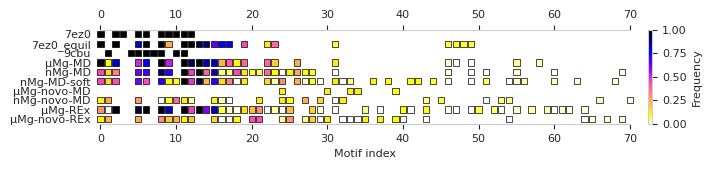

In [16]:
n_motifs = len(p)
n_sims = len(p.columns)

fig, ax = plt.subplots(figsize=(17.8*cm,4*cm))

ax.invert_yaxis()
ax.grid(None)

p_ = p.iloc[:n_motifs]

#group = p_.index[0][0]
for i, (ndx, row) in enumerate(p_.iterrows()):
    ax.scatter(np.ones(n_sims) * i, np.arange(n_sims), c=row, cmap='gnuplot2_r', edgecolors='k', s=20, marker='s', vmin=0, vmax=1, clip_on=False, linewidths=0.5)
    #if ndx[0] != group:
    #    group = ndx[0]
    #    ax.axvline(i-0.5, ls='dashed', color='lightgray', lw=1)

ax.tick_params(top=True, labeltop=True, bottom=True, labelbottom=True)
ax.spines[['left', 'right']].set_visible(False)
ax.set_yticks(range(n_sims), p.columns)
#ax.set_xticks(range(len(p_)), motif_latex.loc[p_.index.get_level_values('motif')], rotation=45)

ax.set_xlabel('Motif index')
ax.set_xlim(0, n_motifs-1)
ax.set_ylim(n_sims-0.5, -0.5)

cax = plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='gnuplot2_r'), ax=ax, pad=0.02, fraction=0.01, label='Frequency')
#fig.savefig('figures/motif_analysis.pdf')

In [14]:
# Vertical layout

# n_motifs = 40
# n_sims = len(p.columns)

# fig, ax = plt.subplots(figsize=(8.7*cm, 25*cm))

# ax.invert_yaxis()
# ax.grid(None)

# p_ = p.iloc[:n_motifs]

# group = p_.index[0][0]
# for i, (ndx, row) in enumerate(p_.iterrows()):
#     ax.scatter(np.arange(n_sims), np.ones(n_sims) * i, c=row, cmap='gnuplot2_r', edgecolors='k', s=80, marker='s', vmin=0, vmax=1)
#     if ndx[0] != group:
#         group = ndx[0]
#         ax.axhline(i-0.5, ls='dashed', color='lightgray')

# ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
# ax.set_xticks(range(n_sims), p.columns, rotation=45, ha='left')
# #ax.set_xticks(range(len(p_)), motif_latex.loc[p_.index.get_level_values('motif')], rotation=45)


# from matplotlib.cm import ScalarMappable
# from matplotlib.colors import Normalize
# cax = plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='gnuplot2_r'), ax=ax, pad=0.01, label='Frequency', orientation='horizontal')

# fig.savefig('figures/motif_analysis.pdf')

In [15]:
compute = False